#Step 1: Import Libraries and Set Device

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from google.colab import drive

In [ ]:
# Set random seed for reproducibility
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


# Step 2: Load Train and Test CSV

Load the patient-independent training and test image records generated in `02_preprocessing.ipynb`. Verify the number of images, class labels, and patient independence before model training.

In [ ]:
# Mount Google Drive
drive.mount("/content/drive")

# Set dataset paths
split_folder = "/content/drive/MyDrive/COMP3710/project/dataset/splits"

train_path = os.path.join(split_folder, "train.csv")
test_path = os.path.join(split_folder, "test.csv")

# Load training and test records
train_df = pd.read_csv(
    train_path,
    dtype={"image_id": str, "patient_id": str}
)

test_df = pd.read_csv(
    test_path,
    dtype={"image_id": str, "patient_id": str}
)

# Check dataset sizes
print("Train images:", len(train_df))
print("Test images:", len(test_df))

# Check class distributions
print("\nTrain class distribution:")
print(train_df["label"].value_counts())

print("\nTest class distribution:")
print(test_df["label"].value_counts())

# Verify patient independence
train_patients = set(train_df["patient_id"])
test_patients = set(test_df["patient_id"])

overlap = train_patients & test_patients

print("\nOverlapping patients:", len(overlap))

assert len(overlap) == 0

print("PASS: Train and Test are patient-independent.")

Mounted at /content/drive
Train images: 17340
Test images: 6220

Train class distribution:
label
NC    9160
AD    8180
Name: count, dtype: int64

Test class distribution:
label
AD    3440
NC    2780
Name: count, dtype: int64

Overlapping patients: 0
PASS: Train and Test are patient-independent.


# Step 2.1: Extract MRI Images Locally

Extract the MRI images from ZIP files stored in Google Drive into Colab local storage to reduce data loading time during CNN training.

In [ ]:
# import os
# import shutil
# import time

# # Set local cache folder
# cache_folder = "/content/mri_cache"

# os.makedirs(cache_folder, exist_ok=True)

# # Combine train and test records
# all_df = pd.concat([train_df, test_df], ignore_index=True)

# start_time = time.time()

# # Copy MRI images to local storage
# for i in range(len(all_df)):

#     source_path = all_df.iloc[i]["path"]

#     # Preserve original train/test and AD/NC folder structure
#     relative_path = os.path.relpath(
#         source_path,
#         "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"
#     )

#     destination_path = os.path.join(cache_folder, relative_path)

#     os.makedirs(
#         os.path.dirname(destination_path),
#         exist_ok=True
#     )

#     if not os.path.exists(destination_path):
#         shutil.copy2(source_path, destination_path)

#     if (i + 1) % 1000 == 0:
#         print(f"Copied {i + 1}/{len(all_df)} images", flush=True)

# elapsed_time = time.time() - start_time

# print("Caching completed.")
# print("Total images:", len(all_df))
# print("Time:", elapsed_time, "seconds")

import os
import zipfile
import time

# Set dataset paths
source_folder = "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"
cache_folder = "/content/mri_cache"

start_time = time.time()

# Extract training and test ZIP files
for split in ["train", "test"]:

    for label in ["AD", "NC"]:

        zip_path = os.path.join(
            source_folder, split, label + ".zip"
        )

        output_folder = os.path.join(
            cache_folder, split, label
        )

        os.makedirs(output_folder, exist_ok=True)

        print("Extracting:", zip_path, flush=True)

        with zipfile.ZipFile(zip_path, "r") as zip_file:
            zip_file.extractall(output_folder)

        print("Finished:", split, label, flush=True)

elapsed_time = time.time() - start_time

print("\nExtraction completed.")
print("Time:", elapsed_time, "seconds")

Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/AD.zip
Finished: train AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/train/NC.zip
Finished: train NC
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/AD.zip
Finished: test AD
Extracting: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC/test/NC.zip
Finished: test NC

Extraction completed.
Time: 20.285897254943848 seconds


In [ ]:
# Check extracted folder structure
for split in ["train", "test"]:
    for label in ["AD", "NC"]:

        folder = os.path.join(cache_folder, split, label)

        print("\nFolder:", folder)
        print("First 5 items:", os.listdir(folder)[:5])


Folder: /content/mri_cache/train/AD
First 5 items: ['301816_107.jpeg', '321413_99.jpeg', '311833_88.jpeg', '366568_96.jpeg', '363191_86.jpeg']

Folder: /content/mri_cache/train/NC
First 5 items: ['1069428_83.jpeg', '1136580_86.jpeg', '900932_104.jpeg', '974132_99.jpeg', '943663_84.jpeg']

Folder: /content/mri_cache/test/AD
First 5 items: ['388976_88.jpeg', '416701_96.jpeg', '423655_87.jpeg', '412832_88.jpeg', '1058589_108.jpeg']

Folder: /content/mri_cache/test/NC
First 5 items: ['1214909_112.jpeg', '1254370_91.jpeg', '1254168_104.jpeg', '1185714_99.jpeg', '1359836_85.jpeg']


# Step 2.2: Update Image Paths

Update the training and test image paths to use the local MRI cache. Verify that all cached images exist before creating the PyTorch datasets.

In [ ]:
# Set original dataset folder
original_folder = "/content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC"

# Update training image paths
for i in range(len(train_df)):

    original_path = train_df.iloc[i]["path"]

    relative_path = os.path.relpath(
        original_path,
        original_folder
    )

    local_path = os.path.join(cache_folder, relative_path)

    train_df.at[train_df.index[i], "path"] = local_path

# Update test image paths
for i in range(len(test_df)):

    original_path = test_df.iloc[i]["path"]

    relative_path = os.path.relpath(
        original_path,
        original_folder
    )

    local_path = os.path.join(cache_folder, relative_path)

    test_df.at[test_df.index[i], "path"] = local_path

# Verify local image paths
missing_train = 0
missing_test = 0

for path in train_df["path"]:
    if not os.path.isfile(path):
        missing_train += 1

for path in test_df["path"]:
    if not os.path.isfile(path):
        missing_test += 1

print("Missing train images:", missing_train)
print("Missing test images:", missing_test)

print("\nExample local path:")
print(train_df.iloc[0]["path"])

assert missing_train == 0
assert missing_test == 0

print("\nPASS: All image paths point to local cached files.")

Missing train images: 0
Missing test images: 0

Example local path:
/content/mri_cache/train/AD/218391_78.jpeg

PASS: All image paths point to local cached files.


In [ ]:
# Find missing training images
for path in train_df["path"]:

    if not os.path.isfile(path):
        print("Missing image:", path)

In [ ]:
# Check original and duplicate images
folder = "/content/mri_cache/train/NC"

original = os.path.join(folder, "976382_96.jpeg")
duplicate = os.path.join(folder, "976382_96 (1).jpeg")

print("Original exists:", os.path.isfile(original))
print("Duplicate exists:", os.path.isfile(duplicate))

Original exists: True
Duplicate exists: False


# Step 3: Define Image Transforms

Resize grayscale MRI images to 128 × 128 pixels, convert them into PyTorch tensors, and normalize pixel intensities for CNN training. The same preprocessing will be applied to the GFNet model for a fair comparison.

In [ ]:
# Set image size
image_size = 128

# Define image preprocessing
image_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

print("Image transform:")
print(image_transform)

Image transform:
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5], std=[0.5])
)


# Step 4: Create PyTorch Dataset

Define a custom PyTorch Dataset to load MRI images from the CSV records, apply image preprocessing, and convert AD/NC labels into numerical values for binary classification.

In [ ]:
class MRIDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        # Convert class labels to numbers
        self.label_map = {
            "NC": 0,
            "AD": 1
        }

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get one image record
        record = self.dataframe.iloc[idx]

        # Load image as grayscale
        image = Image.open(record["path"]).convert("L")

        # Apply preprocessing
        if self.transform is not None:
            image = self.transform(image)

        # Convert label to integer
        label = self.label_map[record["label"]]

        return image, label

In [ ]:
# Create datasets
train_dataset = MRIDataset(
    dataframe=train_df,
    transform=image_transform
)

test_dataset = MRIDataset(
    dataframe=test_df,
    transform=image_transform
)

print("Train dataset size:", len(train_dataset))
print("Test dataset size:", len(test_dataset))

Train dataset size: 17340
Test dataset size: 6220


In [ ]:
# Load one sample
sample_image, sample_label = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)
print("Label:", sample_label)
print("Pixel range:", sample_image.min().item(), sample_image.max().item())

Image shape: torch.Size([1, 128, 128])
Image dtype: torch.float32
Label: 1
Pixel range: -1.0 0.686274528503418


# Step 5: Create DataLoaders

Create training and test DataLoaders to load MRI images in batches. Shuffle the training data for model learning while keeping the test data in a fixed order for evaluation.

In [ ]:
# Set batch size
batch_size = 32

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 542
Test batches: 195


In [ ]:
# Load one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("First 10 labels:", labels[:10])

Batch image shape: torch.Size([32, 1, 128, 128])
Batch label shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
First 10 labels: tensor([1, 1, 0, 1, 0, 1, 0, 1, 1, 1])


# Step 6: Build CNN Model

Define a CNN baseline with three convolutional blocks for extracting spatial features from grayscale MRI images. Global average pooling and a fully connected layer are used to predict the two classes: Normal Control (NC) and Alzheimer's Disease (AD).

In [ ]:
class CNNBaseline(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional feature extraction
        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Global average pooling
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification layer
        self.classifier = nn.Linear(128, 2)

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x

In [ ]:
# Create CNN model
model = CNNBaseline().to(device)

print(model)

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters())

print("\nTotal parameters:", total_params)

CNNBaseline(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)

Total parameters: 92930


In [ ]:
# Test forward pass
images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 128, 128])
Output shape: torch.Size([32, 2])


# Step 7: Train CNN Model

Train the CNN baseline using cross-entropy loss and the Adam optimizer. Record training loss and accuracy for each epoch to monitor model learning. The test set is reserved for final evaluation.

In [ ]:
# Set training parameters
epochs = 10
learning_rate = 0.001

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Store training history
train_loss_history = []
train_acc_history = []

print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Loss function:", criterion)
print("Optimizer: Adam")

Epochs: 10
Learning rate: 0.001
Loss function: CrossEntropyLoss()
Optimizer: Adam


In [ ]:
print("Train loader:", len(train_loader))
print("Model device:", next(model.parameters()).device)

Train loader: 542
Model device: cuda:0


In [ ]:
# Train CNN model
for epoch in range(epochs):

    # Set model to training mode
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Compute loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate loss weighted by batch size
        total_loss += loss.item() * images.size(0)

        # Get predicted classes
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Calculate average loss and accuracy
    epoch_loss = total_loss / total
    epoch_acc = correct / total

    # Save training history
    train_loss_history.append(epoch_loss)
    train_acc_history.append(epoch_acc)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_acc * 100:.2f}%"
    )

Epoch [1/10] Loss: 0.6549 Accuracy: 60.10%
Epoch [2/10] Loss: 0.5900 Accuracy: 69.28%
Epoch [3/10] Loss: 0.5789 Accuracy: 69.53%
Epoch [4/10] Loss: 0.5677 Accuracy: 70.90%
Epoch [5/10] Loss: 0.5610 Accuracy: 71.50%
Epoch [6/10] Loss: 0.5579 Accuracy: 71.57%
Epoch [7/10] Loss: 0.5505 Accuracy: 72.17%
Epoch [8/10] Loss: 0.5447 Accuracy: 72.55%
Epoch [9/10] Loss: 0.5388 Accuracy: 72.98%
Epoch [10/10] Loss: 0.5304 Accuracy: 73.61%


In [ ]:
# import time

# # Measure DataLoader speed
# start_time = time.time()

# for batch_idx, (images, labels) in enumerate(train_loader):

#     if batch_idx == 9:
#         break

# elapsed_time = time.time() - start_time

# print("Time for 10 batches:", elapsed_time, "seconds")
# print("Average time per batch:", elapsed_time / 10, "seconds")

Time for 10 batches: 0.2756919860839844 seconds
Average time per batch: 0.02756919860839844 seconds


In [ ]:
# import time

# # Create one batch directly on GPU
# images = torch.randn(32, 1, 128, 128, device=device)
# labels = torch.randint(0, 2, (32,), device=device)

# model.train()

# # Warm up GPU
# for i in range(3):
#     optimizer.zero_grad()
#     outputs = model(images)
#     loss = criterion(outputs, labels)
#     loss.backward()
#     optimizer.step()

# torch.cuda.synchronize()

# # Forward pass
# start = time.time()

# outputs = model(images)
# loss = criterion(outputs, labels)

# torch.cuda.synchronize()
# print("Forward time:", time.time() - start)

# # Backward pass
# optimizer.zero_grad()
# start = time.time()

# loss.backward()

# torch.cuda.synchronize()
# print("Backward time:", time.time() - start)

# # Optimizer step
# start = time.time()

# optimizer.step()

# torch.cuda.synchronize()
# print("Optimizer time:", time.time() - start)

Forward time: 0.0011129379272460938
Backward time: 0.0036847591400146484
Optimizer time: 0.0006296634674072266


In [ ]:
# import time

# # Set model to training mode
# model.train()

# # 1. Load one batch from DataLoader
# start = time.time()

# images, labels = next(iter(train_loader))

# print("Data loading time:", time.time() - start, "seconds", flush=True)

# # 2. Transfer batch to GPU
# start = time.time()

# images = images.to(device)
# labels = labels.to(device)

# torch.cuda.synchronize()

# print("GPU transfer time:", time.time() - start, "seconds", flush=True)

# # 3. Forward pass
# start = time.time()

# outputs = model(images)
# loss = criterion(outputs, labels)

# torch.cuda.synchronize()

# print("Forward time:", time.time() - start, "seconds", flush=True)

# # 4. Backward pass
# optimizer.zero_grad()

# start = time.time()

# loss.backward()

# torch.cuda.synchronize()

# print("Backward time:", time.time() - start, "seconds", flush=True)

# # 5. Optimizer step
# start = time.time()

# optimizer.step()

# torch.cuda.synchronize()

# print("Optimizer time:", time.time() - start, "seconds", flush=True)

Data loading time: 0.13584184646606445 seconds
GPU transfer time: 0.0018546581268310547 seconds
Forward time: 0.0018069744110107422 seconds
Backward time: 0.004027366638183594 seconds
Optimizer time: 0.0011789798736572266 seconds


In [ ]:
# import time

# # Set model to training mode
# model.train()

# # Measure training speed
# start_time = time.time()

# for batch_idx, (images, labels) in enumerate(train_loader):

#     # Move data to GPU
#     images = images.to(device)
#     labels = labels.to(device)

#     # Clear gradients
#     optimizer.zero_grad()

#     # Forward pass
#     outputs = model(images)

#     # Calculate loss
#     loss = criterion(outputs, labels)

#     # Backward pass
#     loss.backward()

#     # Update parameters
#     optimizer.step()

#     # Stop after 10 batches
#     if batch_idx == 9:
#         break

# # Wait for GPU operations to finish
# if torch.cuda.is_available():
#     torch.cuda.synchronize()

# elapsed_time = time.time() - start_time

# print("Time for 10 training batches:", elapsed_time, "seconds")
# print("Average time per training batch:", elapsed_time / 10, "seconds")

Time for 10 training batches: 0.2785518169403076 seconds
Average time per training batch: 0.027855181694030763 seconds


#Step 8: Visualize CNN Training Results

Plot the training loss and accuracy across epochs to examine the learning progress of the CNN baseline.

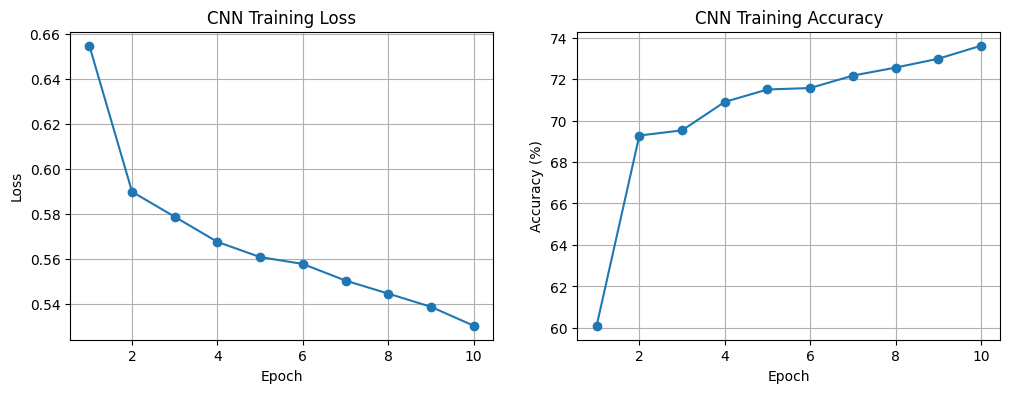

In [ ]:
import matplotlib.pyplot as plt

# Create epoch numbers
epoch_numbers = []

for i in range(len(train_loss_history)):
    epoch_numbers.append(i + 1)


# Convert accuracy to percentage
train_acc_percent = []

for acc in train_acc_history:
    train_acc_percent.append(acc * 100)


# Create two plots
plt.figure(figsize=(12, 4))


# Plot training loss
plt.subplot(1, 2, 1)

plt.plot(epoch_numbers, train_loss_history, marker="o")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss")
plt.grid(True)


# Plot training accuracy
plt.subplot(1, 2, 2)

plt.plot(epoch_numbers, train_acc_percent, marker="o")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training Accuracy")
plt.grid(True)


# Adjust layout

# Step 9: Save CNN Model

Save the trained CNN baseline and its training history to Google Drive for reproducibility and future evaluation.

In [ ]:
import os
import torch

# Set output folder
output_folder = "/content/drive/MyDrive/COMP3710/project/models"

os.makedirs(output_folder, exist_ok=True)

# Set model path
model_path = os.path.join(output_folder, "cnn_baseline.pth")

# Save model and training history
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": epochs,
    "learning_rate": learning_rate,
    "train_loss_history": train_loss_history,
    "train_acc_history": train_acc_history
}, model_path)

print("CNN model saved to:", model_path)
print("File size:", os.path.getsize(model_path), "bytes")

CNN model saved to: /content/drive/MyDrive/COMP3710/project/models/cnn_baseline.pth
File size: 1126145 bytes
